In [3]:
# %% [BLOCK 1] TRAIN AND SAVE
"""
Trains DenseNet121 (Phase 1: head only, Phase 2: fine-tune top layers)
and saves a self-contained joblib bundle (architecture + weights + metadata).
A .keras copy is also saved as a backup.
"""
import os
import warnings
import joblib
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import DenseNet121

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
TRAIN_DIR   = "training"
JOBLIB_PATH = "brain_mri_densenet.joblib"
KERAS_PATH  = "brain_mri_densenet.keras"

CLASS_NAMES = ["notumor", "glioma", "meningioma", "pituitary"]
IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
SEED        = 42
EPOCHS_P1   = 20
EPOCHS_P2   = 30
UNFREEZE_N  = 50          # number of top backbone layers to fine-tune

tf.keras.utils.set_random_seed(SEED)


def load_train_val():
    kw = dict(labels="inferred", label_mode="int", class_names=CLASS_NAMES,
              image_size=IMG_SIZE, batch_size=BATCH_SIZE,
              validation_split=0.2, seed=SEED)
    train_ds = tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, subset="training", **kw)
    val_ds   = tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, subset="validation", **kw)
    return train_ds.prefetch(tf.data.AUTOTUNE), val_ds.prefetch(tf.data.AUTOTUNE)


def class_weights_from_folders():
    counts = np.array([
        len([f for f in os.listdir(os.path.join(TRAIN_DIR, c)) if not f.startswith(".")])
        for c in CLASS_NAMES
    ], dtype=float)
    weights = counts.sum() / (len(CLASS_NAMES) * counts)
    return {i: float(w) for i, w in enumerate(weights)}


def build_model():
    inputs = layers.Input(shape=(*IMG_SIZE, 3))          # raw pixels 0-255

    # Augmentation: Keras applies it ONLY during fit(), never at inference
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomContrast(0.2)(x)

    # DenseNet preprocessing (ImageNet mean/std on 0-1 scale), done with layers
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Normalization(mean=[0.485, 0.456, 0.406],
                             variance=[0.229**2, 0.224**2, 0.225**2])(x)

    backbone = DenseNet121(weights="imagenet", include_top=False,
                           input_shape=(*IMG_SIZE, 3), name="densenet121")
    backbone.trainable = False
    x = backbone(x, training=False)                      # BN stays in inference mode

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation="relu",
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu",
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
    return models.Model(inputs, outputs), backbone


def make_callbacks(ckpt_path):
    return [
        callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=4, min_lr=1e-7, verbose=1),
    ]


def main():
    train_ds, val_ds = load_train_val()
    cw = class_weights_from_folders()
    print("Class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in cw.items()})

    model, backbone = build_model()

    # ---- Phase 1: head only ----
    print("\n=== PHASE 1: training head (frozen backbone) ===")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P1,
                   class_weight=cw, callbacks=make_callbacks("phase1_best.keras"))

    # ---- Phase 2: fine-tune top layers (BatchNorm layers stay frozen) ----
    print("\n=== PHASE 2: fine-tuning top DenseNet layers ===")
    backbone.trainable = True
    for layer in backbone.layers[:-UNFREEZE_N]:
        layer.trainable = False
    for layer in backbone.layers[-UNFREEZE_N:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P2,
                   class_weight=cw, callbacks=make_callbacks("phase2_best.keras"))

    # ---- Save ----
    model.save(KERAS_PATH)
    bundle = {
        "architecture": model.to_json(),
        "weights": model.get_weights(),
        "class_names": CLASS_NAMES,
        "img_size": IMG_SIZE,
        "history": {"phase1": h1.history, "phase2": h2.history},
    }
    joblib.dump(bundle, JOBLIB_PATH, compress=3)
    print(f"\nSaved: {JOBLIB_PATH}  (+ backup {KERAS_PATH})")


if __name__ == "__main__":
    main()

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Class weights: {'notumor': 1.0, 'glioma': 1.0, 'meningioma': 1.0, 'pituitary': 1.0}

=== PHASE 1: training head (frozen backbone) ===
Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 680ms/step - accuracy: 0.7069 - loss: 0.9563
Epoch 1: val_loss improved from None to 0.76233, saving model to phase1_best.keras

Epoch 1: finished saving model to phase1_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 125s 860ms/step - accuracy: 0.7871 - loss: 0.7244 - val_accuracy: 0.7705 - val_loss: 0.7623 - learning_rate: 0.0010
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 771ms/step - accuracy: 0.8437 - loss: 0.5416
Epoch 2: val_loss improved from 0.76233 to 0.50608, saving model to phase1_best.keras

Epoch 2: finished saving model to phase1_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 137s 976ms/step - accuracy: 0.8435 - loss: 0.5178 - val_accuracy: 0.8295 - val_loss: 0.5061 - l

Found 1600 files belonging to 4 classes.
50/50 ━━━━━━━━━━━━━━━━━━━━ 33s 636ms/step

Evaluated on 1600 test images

MULTICLASS (tumor type)
Accuracy      : 88.25%
Macro AUC-ROC : 0.9789

              precision    recall  f1-score   support

     notumor     0.9192    0.9950    0.9556       400
      glioma     0.9228    0.7775    0.8440       400
  meningioma     0.8532    0.7700    0.8095       400
   pituitary     0.8422    0.9875    0.9091       400

    accuracy                         0.8825      1600
   macro avg     0.8844    0.8825    0.8795      1600
weighted avg     0.8844    0.8825    0.8795      1600

Confusion matrix:
 [[398   1   0   1]
 [ 27 311  48  14]
 [  8  25 308  59]
 [  0   0   5 395]]

BINARY (tumor detection)
Accuracy            : 97.69%
Sensitivity (recall): 97.08%   <- tumors correctly flagged
Specificity         : 99.50%
Missed tumors (FN)  : 35
Confusion matrix:
 [[ 398    2]
 [  35 1165]]


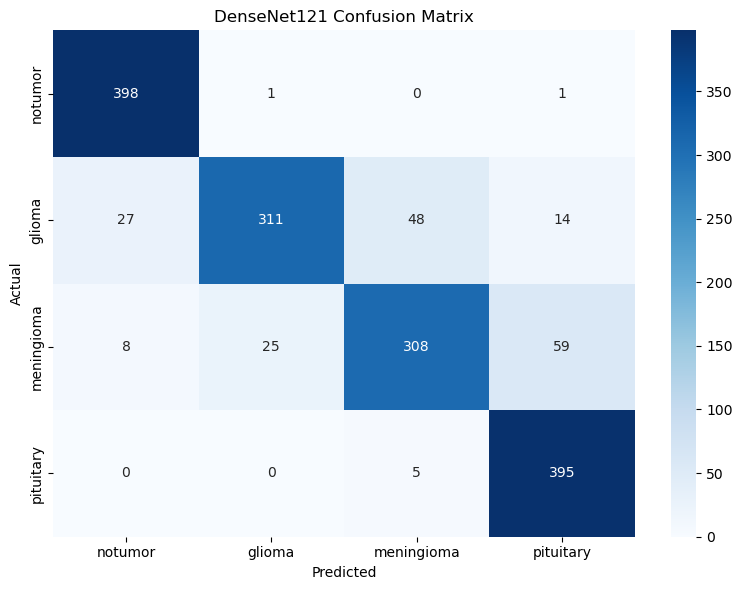


Saved: confusion_matrix.png, brain_mri_results.xlsx


In [5]:
# %% [BLOCK 3] STATS ON THE TEST SET
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)

JOBLIB_PATH = "brain_mri_densenet.joblib"
TEST_DIR    = "testing"
EXCEL_PATH  = "brain_mri_results.xlsx"
BATCH_SIZE  = 32


def run_stats():
    b = joblib.load(JOBLIB_PATH)
    model = tf.keras.models.model_from_json(b["architecture"])
    model.set_weights(b["weights"])
    class_names, img_size = b["class_names"], tuple(b["img_size"])
    labels = list(range(len(class_names)))

    # shuffle=False keeps predictions aligned with labels
    test_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR, labels="inferred", label_mode="int", class_names=class_names,
        image_size=img_size, batch_size=BATCH_SIZE, shuffle=False)
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    proba = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(proba, axis=1)
    print(f"\nEvaluated on {len(y_true)} test images")

    # ---- 4-class ----
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    report_txt = classification_report(y_true, y_pred, labels=labels, target_names=class_names, digits=4)
    report = classification_report(y_true, y_pred, labels=labels, target_names=class_names, output_dict=True)
    auc = roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=labels)

    print("\n" + "=" * 55 + "\nMULTICLASS (tumor type)\n" + "=" * 55)
    print(f"Accuracy      : {acc*100:.2f}%")
    print(f"Macro AUC-ROC : {auc:.4f}\n")
    print(report_txt)
    print("Confusion matrix:\n", cm)

    # ---- Binary: tumor vs no tumor ----
    yt_b, yp_b = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    cm_b = confusion_matrix(yt_b, yp_b, labels=[0, 1])
    tn, fp, fn, tp = cm_b.ravel()
    print("\n" + "=" * 55 + "\nBINARY (tumor detection)\n" + "=" * 55)
    print(f"Accuracy            : {accuracy_score(yt_b, yp_b)*100:.2f}%")
    print(f"Sensitivity (recall): {tp/(tp+fn)*100:.2f}%   <- tumors correctly flagged")
    print(f"Specificity         : {tn/(tn+fp)*100:.2f}%")
    print(f"Missed tumors (FN)  : {fn}")
    print("Confusion matrix:\n", cm_b)

    # ---- Confusion matrix plot ----
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.title("DenseNet121 Confusion Matrix")
    plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

    # ---- Excel export ----
    df = pd.DataFrame(report).T.loc[class_names + ["macro avg", "weighted avg"]].round(4)
    df["support"] = df["support"].astype(int)
    summary = pd.DataFrame({"Metric": ["Accuracy", "Macro AUC-ROC", "Binary sensitivity", "Binary specificity"],
                            "Value": [round(acc, 4), round(auc, 4), round(tp/(tp+fn), 4), round(tn/(tn+fp), 4)]})
    with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as w:
        df.to_excel(w, sheet_name="Per-class")
        summary.to_excel(w, sheet_name="Summary", index=False)
        pd.DataFrame(cm, index=class_names, columns=class_names).to_excel(w, sheet_name="Confusion")
    print(f"\nSaved: confusion_matrix.png, {EXCEL_PATH}")


if __name__ == "__main__":
    run_stats()